MACHINE LEARNING MINI PROJECT

Classification of Wine Using Machine Learning Algorithms
Introduction
Classification is a supervised machine learning technique used to predict the category or class of new data using labelled training data.
Objective
To classify wine samples into one of three wine classes using four classification algorithms and compare their accuracy.
Dataset
This project uses the Wine Recognition Dataset from Scikit-learn. It contains 178 wine samples, 13 numerical input features and 3 target classes. This is not the Iris dataset.
Algorithms Used
1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Support Vector Machine (SVM)


Step 1: Import required libraries

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

Step 2: Load the dataset

In [14]:
# Load Wine Recognition dataset
wine = load_wine(as_frame=True)

# Convert dataset into a DataFrame
df = wine.frame

# Display first five rows
print(df.head())

# Display dataset information
print("\\nDataset Shape:", df.shape)
print("\\nColumn Names:")
print(df.columns)

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

Step 3: Data preprocessing

Separate the input features (X) and target output (y). The target contains three wine classes: 0, 1 and 2.

In [15]:
# Input features
X = df.drop('target', axis=1)

# Target variable
y = df['target']

print("Input Features:")
print(X.head())

print("\\nTarget Classes:")
print(y.value_counts().sort_index())

Input Features:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0  

Step 4: Split the dataset

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (142, 13)
Testing Data: (36, 13)


Step 5: Preprocessing numerical data

In [17]:
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

Step 6: Logistic Regression

In [18]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred))
print("LOGISTIC REGRESSION")
print(classification_report(y_test, lr_pred))

Logistic Regression Accuracy: 0.9722222222222222
LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



Step 7: Decision Tree

In [19]:
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=15,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred))
print("DECISION TREE")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 0.9444444444444444
DECISION TREE
              precision    recall  f1-score   support

           0       1.00      0.92      0.96        12
           1       0.88      1.00      0.93        14
           2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



Step 8: K-Nearest Neighbors (KNN)

In [20]:
knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred))
print("KNN")
print(classification_report(y_test, knn_pred))

KNN Accuracy: 0.9722222222222222
KNN
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      0.93      0.96        14
           2       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



Step 9: Support Vector Machine (SVM)

In [21]:
svm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

print("SVM Accuracy:",
      accuracy_score(y_test, svm_pred))
print("SVM")
print(classification_report(y_test, svm_pred))

SVM Accuracy: 0.9722222222222222
SVM
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



Step 10: Compare all four algorithms

In [22]:
results = pd.DataFrame({
    'Algorithm': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'SVM'
    ],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ]
})

print(results)

             Algorithm  Accuracy
0  Logistic Regression  0.972222
1        Decision Tree  0.944444
2                  KNN  0.972222
3                  SVM  0.972222


Step 11: Visualize accuracy comparison

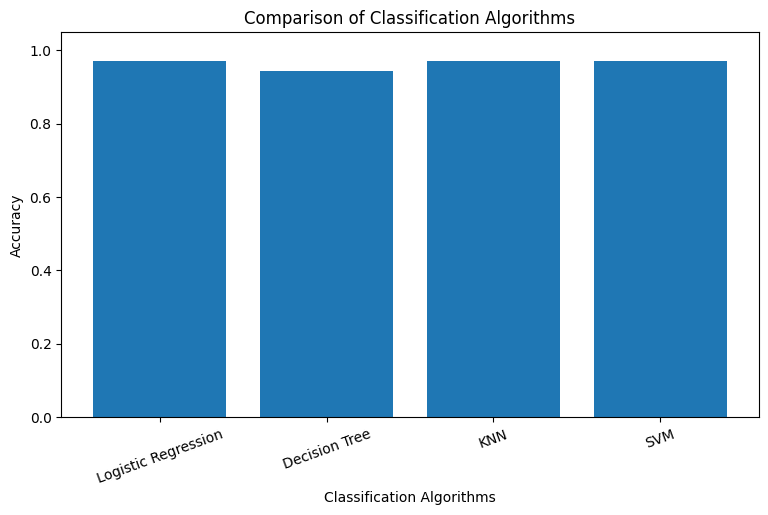

In [23]:
plt.figure(figsize=(9, 5))
plt.bar(results['Algorithm'], results['Accuracy'])

plt.xlabel('Classification Algorithms')
plt.ylabel('Accuracy')
plt.title('Comparison of Classification Algorithms')

plt.xticks(rotation=20)
plt.ylim(0, 1.05)
plt.show()

Step 12: Confusion matrices

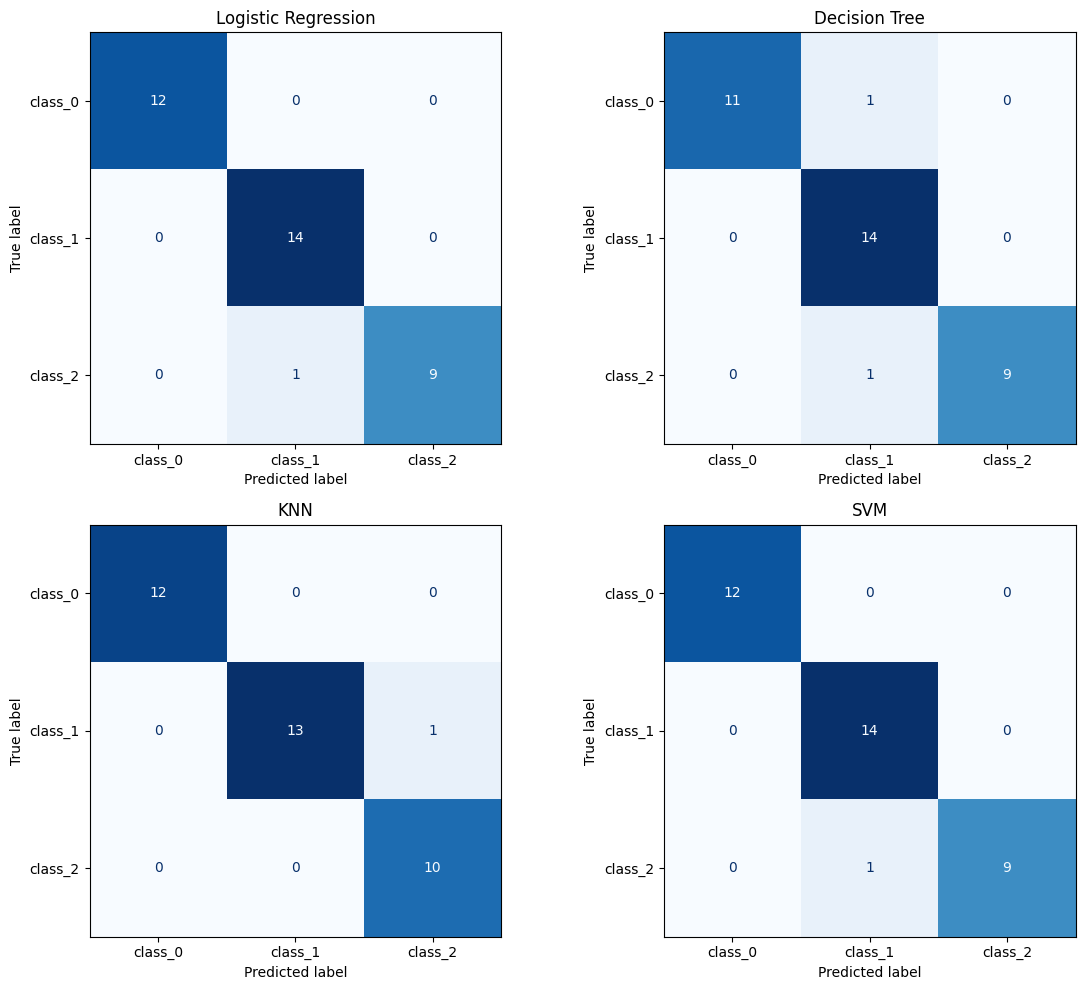

In [24]:
models = {
    'Logistic Regression': lr_pred,
    'Decision Tree': dt_pred,
    'KNN': knn_pred,
    'SVM': svm_pred
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, predictions) in enumerate(models.items()):
    cm = confusion_matrix(y_test, predictions)
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=wine.target_names
    )
    display.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

Conclusion
The Wine Recognition Dataset was classified using Logistic Regression, Decision Tree, KNN and SVM. Their accuracy values were compared using a table and bar graph. The confusion matrices were also used to evaluate the predictions.

Note: Accuracy may vary slightly with changes in the dataset split or software version.